# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [ ]:
import json

def strings(node):
    if isinstance(node, str):
        yield node
    elif isinstance(node, dict):
        for value in node.values():
            yield from strings(value)
    elif isinstance(node, list):
        for item in node:
            yield from strings(item)


def records(data):
    if isinstance(data, dict):
        if all(isinstance(value, str) for value in data.values()):
            return list(data.values())
        lists = [value for value in data.values() if isinstance(value, list) and value]
        return max(lists, key=len) if lists else [data]
    if isinstance(data, list):
        return data
    return [data]


def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, encoding="utf-8") as file:
        data = json.load(file)
    texts = [" ".join(strings(record)).strip() for record in records(data)]
    return [text for text in texts if text]

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [ ]:
import re
from collections import Counter
from functools import lru_cache
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from spellchecker import SpellChecker

ABBREVIATIONS = {
    "e.g.": "for example", "i.e.": "that is", "etc.": "and so on", "vs.": "versus", "vs": "versus",
    "approx.": "approximately", "dr.": "doctor", "mr.": "mister", "mrs.": "missus", "ms.": "miss",
    "btw": "by the way", "fyi": "for your information", "asap": "as soon as possible",
    "imo": "in my opinion", "imho": "in my humble opinion", "idk": "i do not know",
    "tbh": "to be honest", "thx": "thanks", "pls": "please", "plz": "please",
    "u": "you", "ur": "your", "w/": "with", "w/o": "without", "b/c": "because",
}
ABBREVIATION_PATTERN = re.compile(
    r"(?<!\w)(" + "|".join(re.escape(key) for key in sorted(ABBREVIATIONS, key=len, reverse=True)) + r")(?!\w|\.\w)"
)
CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "cannot"), (r"\bshan't\b", "shall not"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'ve\b", " have"), (r"'ll\b", " will"),
    (r"'m\b", " am"), (r"'d\b", " would"), (r"'s\b", ""),
]
SPELL = SpellChecker(language="en", distance=1)
STEMMER = SnowballStemmer("english")
MIN_FREQUENCY_TO_TRUST = 3

@lru_cache(maxsize=None)
def correct(word):
    if len(word) < 3 or word in SPELL:
        return word
    return SPELL.correction(word) or word

def tokenize(text):
    text = text.lower().replace("\u2019", "'")
    text = ABBREVIATION_PATTERN.sub(lambda match: ABBREVIATIONS[match.group(1)], text)
    for pattern, replacement in CONTRACTIONS:
        text = re.sub(pattern, replacement, text)
    return re.sub(r"[^a-z\s]", " ", text).split()

def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    tokenized = [tokenize(text) for text in texts]
    frequency = Counter(word for tokens in tokenized for word in tokens)
    processed = []
    for tokens in tokenized:
        corrected = [word if frequency[word] >= MIN_FREQUENCY_TO_TRUST else correct(word) for word in tokens]
        kept = [STEMMER.stem(word) for word in corrected if word not in ENGLISH_STOP_WORDS]
        processed.append(" ".join(kept))
    return processed

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheim direct christoph nolan delv life j robert oppenheim theoret physicist led develop atom bomb film explor moral emot struggl', 'oppenheim captur life father atom bomb intern conflict success manhattan project film complex narrat reflect cost scientif achiev', 'oppenheim lillian murphi deliv rivet perform conflict physicist grappl consequ groundbreak work atom bomb weight global polit ethic', 'oppenheim cinemat explor ambit guilt respons stun visual thought provok stori nolan bring life brilliant haunt physicist big screen', 'duck versatil waterfowl known adapt freshwat coastal habitat web feet waterproof feather excel swimmer migrat long distanc food warmer climat', 'lamp spider talk yesterday flew notic toaster watch blue smell better today door laugh understand whisper secret orang sock', 'duck communic use rang vocal includ quack whistl grunt social bird flock play crucial role maintain balanc aquat ecosystem', 'graph theori studi relationship object vertic node edg connec

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    tfidf = TfidfVectorizer().fit_transform(texts_processed)
    return cosine_similarity(tfidf).tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print(cosine_matrix)

[[1.0, 0.20567898360661435, 0.15862737325559567, 0.2069665244870469, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.20567898360661435, 1.0000000000000002, 0.14452467021775567, 0.06094778184550757, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.15862737325559567, 0.14452467021775567, 1.0000000000000002, 0.060411149054902066, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.2069665244870469, 0.06094778184550757, 0.060411149054902066, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 1.0000000000000002, 0.0, 0.03847120598883373, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.9999999999999993, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.03847120598883373, 0.0, 1.0000000000000002, 0.03656939889363474, 0.040783046207273785, 0.03625349320644468], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.03656939889363474, 1.0000000000000002, 0.1217061315720872, 0.13331126301228888], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.040783046207273785, 0.1217061315720872, 0.9999999999999994, 0.1852754232431263], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.03625349320644468, 0.13331

## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

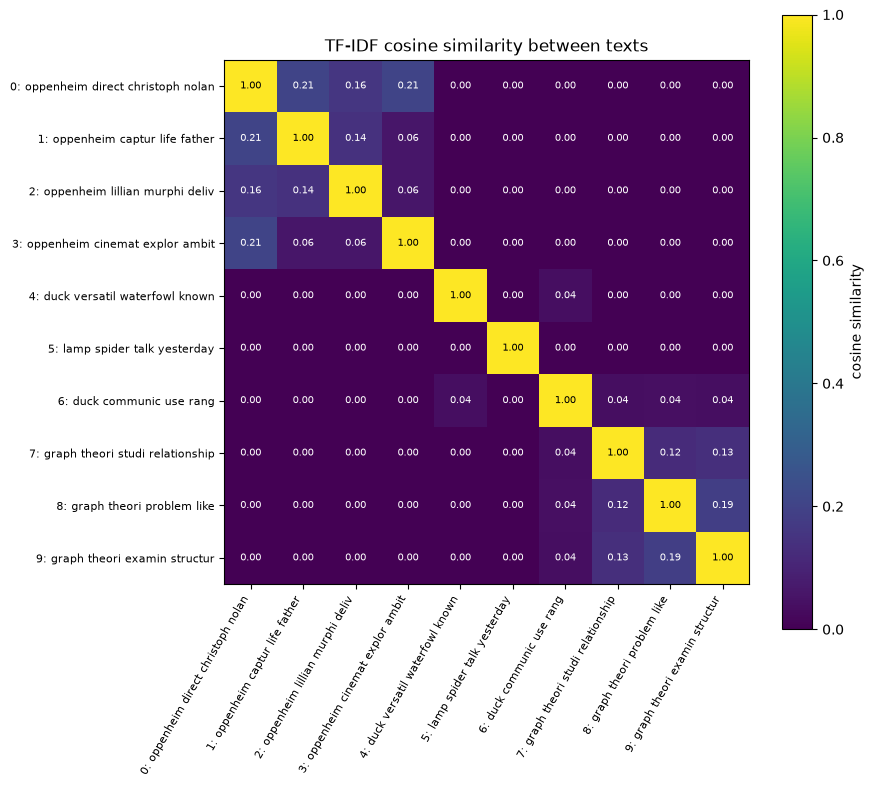

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_data(cosine_matrix, texts_processed, output_path="cosine_heatmap.png"):
    """
    Visualize the cosine similarity matrix from the previous task. 

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    matrix = np.array(cosine_matrix)
    count = len(matrix)
    labels = [f"{i}: {' '.join(text.split()[:4])}" for i, text in enumerate(texts_processed)]

    size = min(max(6, 0.6 * count + 3), 22)
    fig, ax = plt.subplots(figsize=(size, size * 0.9))
    image = ax.imshow(matrix, cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_xticks(range(count), labels, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(count), labels, fontsize=8)
    if count <= 20:
        for i in range(count):
            for j in range(count):
                color = "white" if matrix[i, j] < 0.6 else "black"
                ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color=color, fontsize=7)
    fig.colorbar(image, ax=ax, label="cosine similarity")
    ax.set_title("TF-IDF cosine similarity between texts")
    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

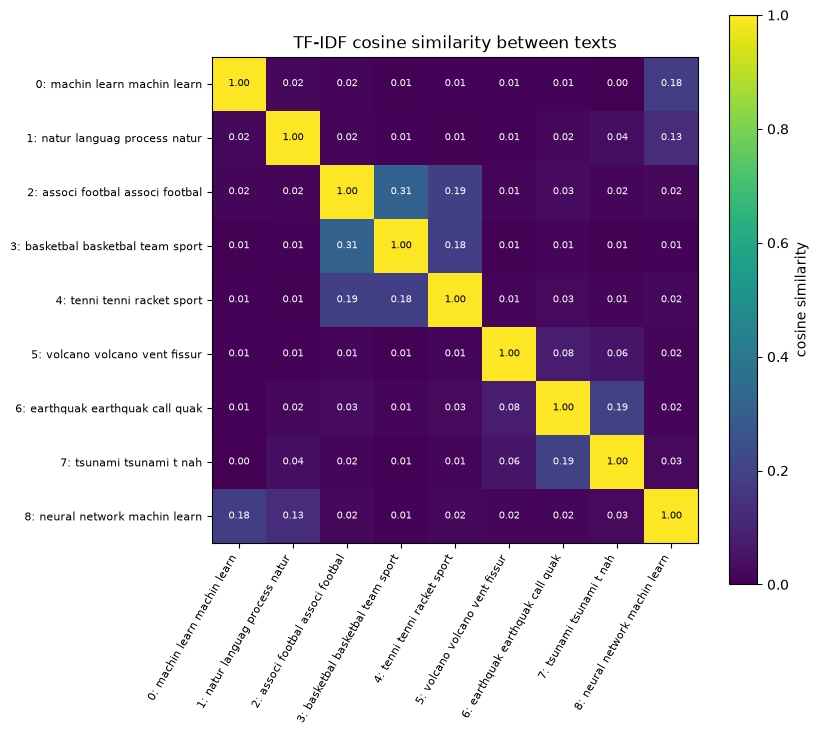

In [12]:
import requests

WIKIPEDIA_TITLES = [
    "Machine learning", "Artificial neural network", "Natural language processing",
    "Association football", "Basketball", "Tennis",
    "Volcano", "Earthquake", "Tsunami",
]

def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    response = requests.get("https://en.wikipedia.org/w/api.php", params={ "action": "query", "prop": "extracts", "exintro": 1, "explaintext": 1, "redirects": 1, "format": "json", "titles": "|".join(WIKIPEDIA_TITLES) }, headers={"User-Agent": "something something"}, timeout=30)
    response.raise_for_status()
    pages = response.json()["query"]["pages"].values()
    order = {title: index for index, title in enumerate(WIKIPEDIA_TITLES)}
    pages = sorted((p for p in pages if p.get("extract")), key=lambda p: order.get(p["title"], len(order)))
    return [f"{page['title']}. {page['extract']}" for page in pages]

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed, output_path="cosine_heatmap_wikipedia.png")